In [1]:
import numpy as np
from astropy.io import fits
from astropy.table import Table
from matplotlib.colors import LogNorm

import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
from astropy.utils.data import download_file

In [4]:
event_filename = download_file(
    "http://data.astropy.org/tutorials/FITS-tables/chandra_events.fits", cache=True
)

In [5]:
# Opening a FITS file

hdu_list= fits.open(event_filename, memmap= True)
hdu_list.info()

Filename: /home/user/.cache/astropy/download/url/333246bccb141ea3b4e86c49e45bf8d6/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      30   ()      
  1  EVENTS        1 BinTableHDU    890   483964R x 19C   [1D, 1I, 1I, 1J, 1I, 1I, 1I, 1I, 1E, 1E, 1E, 1E, 1J, 1J, 1E, 1J, 1I, 1I, 32X]   
  2  GTI           3 BinTableHDU     28   1R x 2C   [1D, 1D]   
  3  GTI           2 BinTableHDU     28   1R x 2C   [1D, 1D]   
  4  GTI           1 BinTableHDU     28   1R x 2C   [1D, 1D]   
  5  GTI           0 BinTableHDU     28   1R x 2C   [1D, 1D]   
  6  GTI           6 BinTableHDU     28   1R x 2C   [1D, 1D]   


In [6]:
print(hdu_list[1].columns)

ColDefs(
    name = 'time'; format = '1D'; unit = 's'
    name = 'ccd_id'; format = '1I'
    name = 'node_id'; format = '1I'
    name = 'expno'; format = '1J'
    name = 'chipx'; format = '1I'; unit = 'pixel'; coord_type = 'CPCX'; coord_unit = 'mm'; coord_ref_point = 0.5; coord_ref_value = 0.0; coord_inc = 0.023987
    name = 'chipy'; format = '1I'; unit = 'pixel'; coord_type = 'CPCY'; coord_unit = 'mm'; coord_ref_point = 0.5; coord_ref_value = 0.0; coord_inc = 0.023987
    name = 'tdetx'; format = '1I'; unit = 'pixel'
    name = 'tdety'; format = '1I'; unit = 'pixel'
    name = 'detx'; format = '1E'; unit = 'pixel'; coord_type = 'LONG-TAN'; coord_unit = 'deg'; coord_ref_point = 4096.5; coord_ref_value = 0.0; coord_inc = 0.00013666666666667
    name = 'dety'; format = '1E'; unit = 'pixel'; coord_type = 'NPOL-TAN'; coord_unit = 'deg'; coord_ref_point = 4096.5; coord_ref_value = 0.0; coord_inc = 0.00013666666666667
    name = 'x'; format = '1E'; unit = 'pixel'; coord_type = 'RA---TAN'; c

In [8]:
# Converting this into Astropy Table
evt_data= Table(hdu_list[1].data)
evt_data

time,ccd_id,node_id,expno,chipx,chipy,tdetx,tdety,detx,dety,x,y,pha,pha_ro,energy,pi,fltgrade,grade,status
float64,int16,int16,int32,int16,int16,int16,int16,float32,float32,float32,float32,int32,int32,float32,int32,int16,int16,bool[32]
238623220.9093583,3,3,68,920,8,5124,3981,5095.641,4138.995,4168.0723,5087.772,3548,3534,13874.715,951,16,4,False .. False
238623220.9093583,3,1,68,437,237,4895,3498,4865.567,4621.1826,3662.1968,4915.9336,667,629,2621.1938,180,64,2,False .. False
238623220.9093583,3,2,68,719,289,4843,3780,4814.835,4340.254,3935.2207,4832.552,3033,2875,12119.018,831,8,3,False .. False
238623220.9093583,3,0,68,103,295,4837,3164,4807.3643,4954.385,3324.4644,4897.2754,831,773,3253.0364,223,0,0,False .. False
238623220.9093583,3,1,68,498,314,4818,3559,4788.987,4560.3276,3713.6343,4832.735,3612,3439,14214.382,974,64,2,False .. False
238623220.9093583,3,3,68,791,469,4663,3852,4635.4526,4268.053,3985.8496,4645.93,500,438,1952.7239,134,0,0,False .. False
238623220.9093583,3,3,68,894,839,4293,3955,4266.642,4165.3203,4044.5469,4267.605,835,713,3267.5334,224,0,0,False .. False
238623220.9093583,3,3,68,857,941,4191,3918,4164.815,4202.2256,3995.9353,4170.818,975,804,3817.0366,262,0,0,False .. False
238623220.9093583,3,3,68,910,959,4173,3971,4146.9937,4149.364,4046.3376,4146.9106,576,446,2252.7295,155,0,0,False .. False


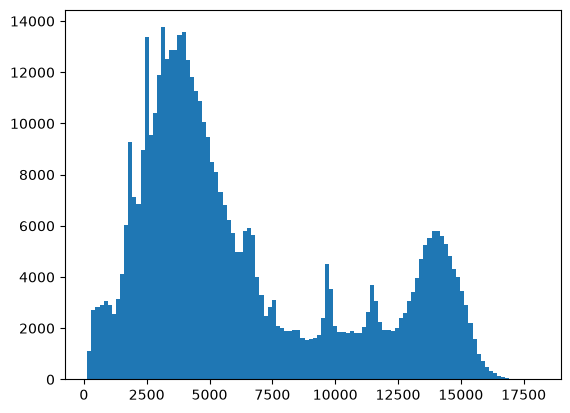

In [14]:
energy_hist = plt.hist(evt_data["energy"], bins="auto")

This particular observation spans five CCD chips. First, we determine the events that only fell on the main (ACIS-I) chips, which have number ids 0, 1, 2, and 3.

In [17]:
# Making a 2D histogram with some table data 
ii = np.isin(evt_data["ccd_id"],[0,1,2,3])
np.sum(ii)

np.int64(434858)

Text(0, 0.5, 'y')

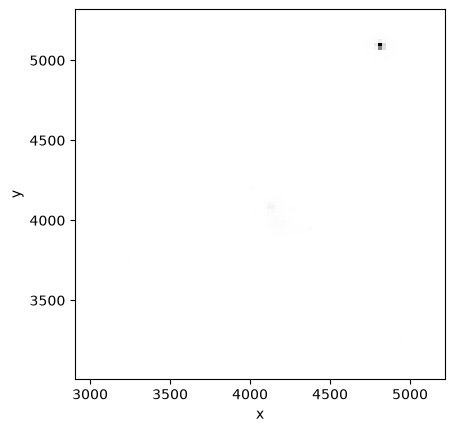

In [23]:
NBINS = (100,100)

img_zero, yedges, xedges = np.histogram2d(evt_data["x"][ii], evt_data["y"][ii], NBINS)

extent= [xedges[0], xedges[-1], yedges[0] , yedges[-1]]

plt.imshow(
    img_zero, extent=extent, interpolation="nearest", cmap="gist_yarg", origin="lower"
)
plt.xlabel("x")
plt.ylabel("y")



Text(0, 0.5, 'y')

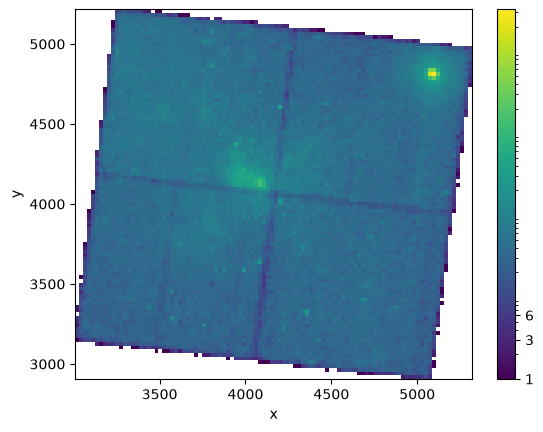

In [24]:
# Use hist2d with a log-normal color scheme

NBINS = (100,100)
img_zero_mpl = plt.hist2d(
    evt_data["x"][ii], evt_data["y"][ii], NBINS, cmap="viridis", norm=LogNorm()

)
cbar = plt.colorbar(ticks=[1.0,3.0,6.0])
cbar.ax.set_yticklabels(["1","3","6"])

plt.xlabel("x")
plt.ylabel("y")


Text(0, 0.5, 'y')

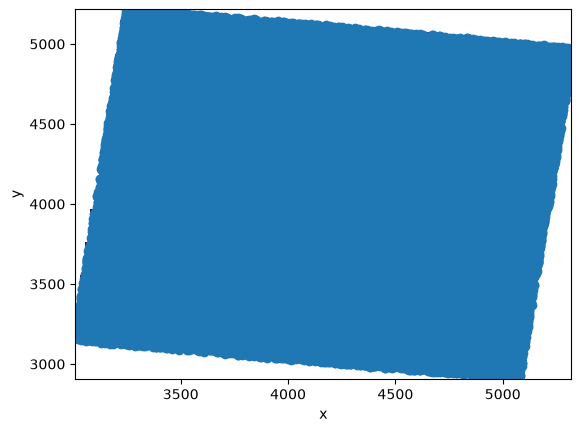

In [28]:
# Use hist2d with a log-normal color scheme

NBINS = (100,100)
img_zero_mpl = plt.hist2d(
    evt_data["x"][ii], evt_data["y"][ii], NBINS, cmap="viridis", norm=LogNorm()

)
cbar = plt.scatter(evt_data["x"][ii], evt_data["y"][ii])
#cbar.ax.set_yticklabels(["1","3","6"])

plt.xlabel("x")
plt.ylabel("y")


# Section:2

In [29]:
from astropy.utils.data import download_file

image_file = download_file(
    "http://data.astropy.org/tutorials/FITS-images/HorseHead.fits", cache=True
)

In [30]:
hdu_list1=  fits.open(image_file)
hdu_list1.info()

Filename: /home/user/.cache/astropy/download/url/ff6e0b93871033c68022ca026a956d87/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     161   (891, 893)   int16   
  1  er.mask       1 TableHDU        25   1600R x 4C   [F6.2, F6.2, F6.2, F6.2]   


In [31]:
# let's just choose primary first
image_data = hdu_list1[0].data

In [33]:
print(type(image_data))
print(image_data.shape)

<class 'numpy.ndarray'>
(893, 891)


In [34]:
# after extracting all information we need , we can close the fits file
hdu_list1.close()


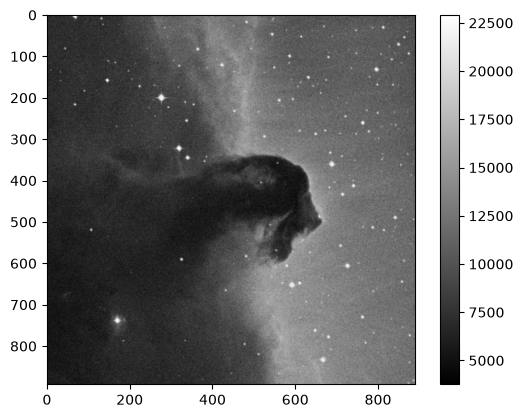

In [36]:
# Viewing the image data and getting basic statistics

plt.imshow(image_data, cmap="gray")
plt.colorbar()

In [37]:
print("Min:", np.min(image_data))
print("Max:", np.max(image_data))
print("Mean:", np.mean(image_data))
print("Stdev:", np.std(image_data))

Min: 3759
Max: 22918
Mean: 9831.481676287574
Stdev: 3032.3927542049046


In [38]:
print(type(image_data.flatten()))
print(image_data.flatten().shape)


<class 'numpy.ndarray'>
(795663,)


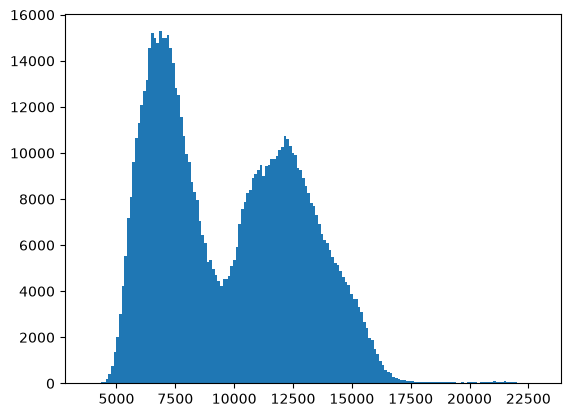

In [39]:
histogram = plt.hist(image_data.flatten(), bins="auto")

[Text(1, 5000.0, '5000'),
 Text(1, 10000.0, '10,000'),
 Text(1, 20000.0, '20,000')]

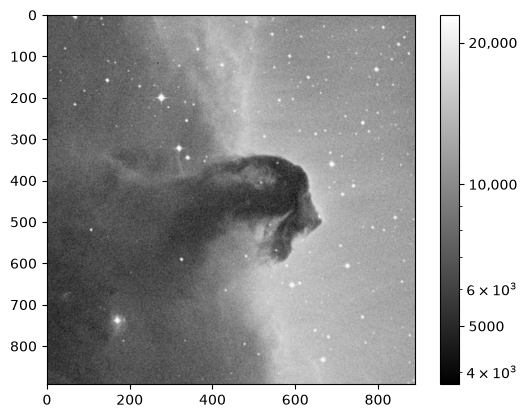

In [40]:
# Displaying an Image with a logarithmic scale

from matplotlib.colors import LogNorm

plt.imshow(image_data, cmap="gray", norm=LogNorm())

cbar = plt.colorbar(ticks=[5.0e3, 1.0e4, 2.0e4])
cbar.ax.set_yticklabels(["5000","10,000","20,000"])


In [42]:
 # Basic image math: image stacking

# Stacking several image using concat
base_url = "http://data.astropy.org/tutorials/FITS-images/M13_blue_{0:04d}.fits"

image_list= [download_file(base_url.format(n), cache= True)for n in range(1,5 + 1)]
image_concat = [fits.getdata(image) for image in image_list]

In [46]:
final_image= np.zeros(shape= image_concat [0].shape)

for image in image_concat:
    final_image += image

# short way
final_image = np.sum(image_concat, axis=0)

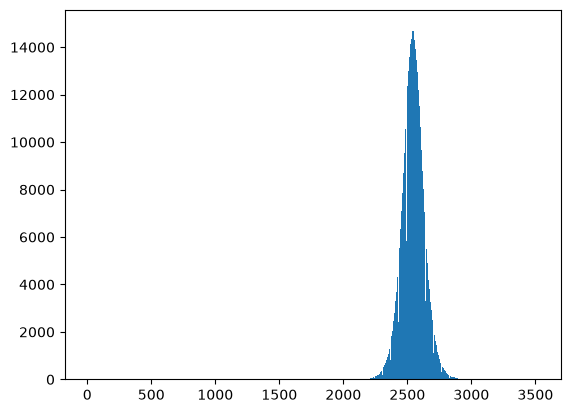

In [47]:
image_hist= plt.hist(final_image.flatten(), bins="auto")

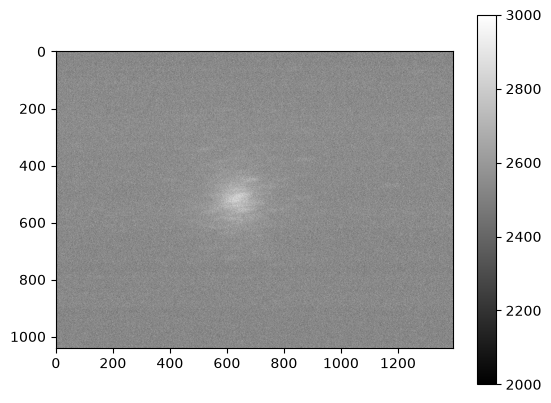

In [48]:
plt.imshow(final_image, cmap="gray", vmin=2e3, vmax=3e3)
plt.colorbar()

Text(0, 0.5, 'Y Pixels')

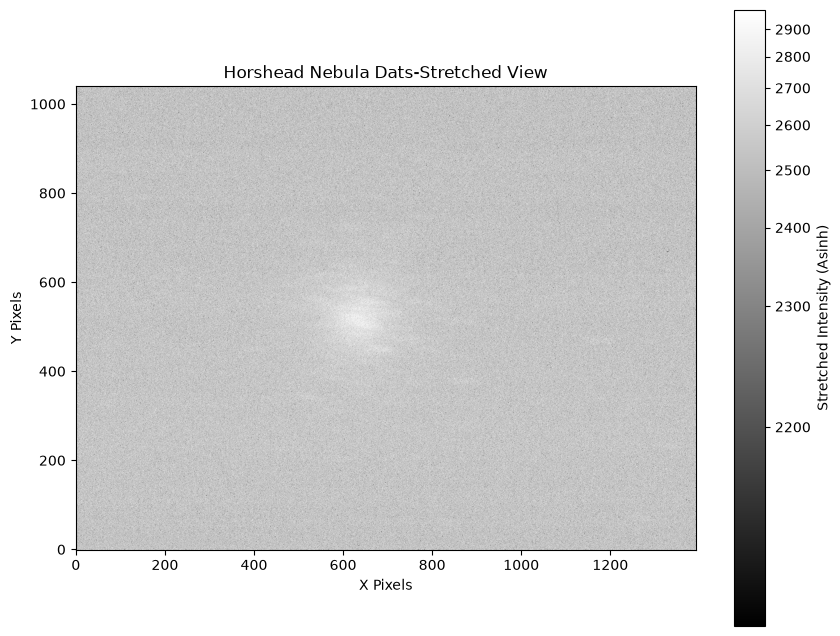

In [51]:
from astropy.visualization import AsinhStretch, ImageNormalize, ZScaleInterval

norm= ImageNormalize (
    final_image,
    interval=ZScaleInterval(),
    stretch= AsinhStretch()
)
plt.figure(figsize=(10,8))
plt.imshow(final_image, cmap= "gray", origin="lower", norm= norm)

plt.colorbar(label="Stretched Intensity (Asinh)")
plt.title("Horshead Nebula Dats-Stretched View")
plt.xlabel("X Pixels")
plt.ylabel("Y Pixels")

Text(0, 0.5, 'Y Pixels')

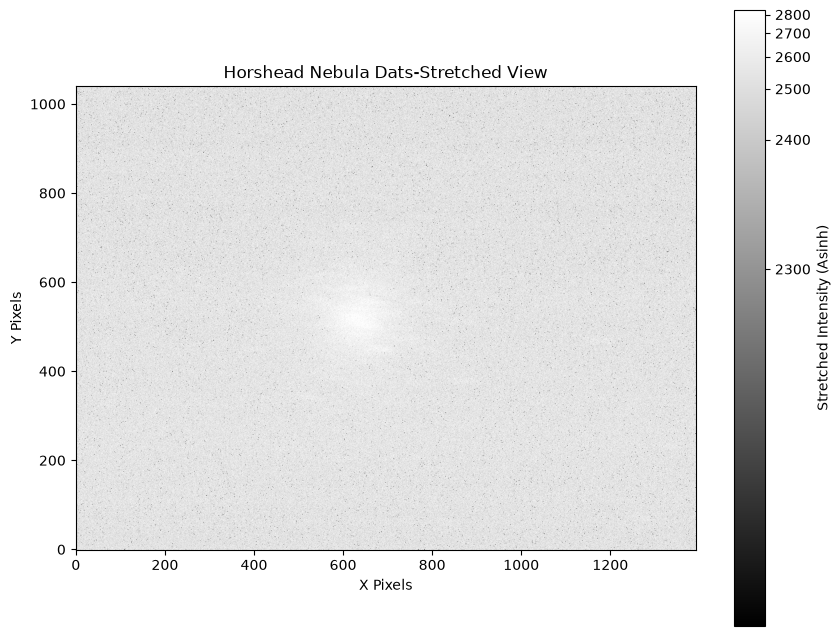

In [ ]:
from astropy.visualization import  ImageNormalize, LogStretch, PercentileInterval
norm= ImageNormalize (
    final_image,
    interval=PercentileInterval(99.5),
    stretch= LogStretch()
)
plt.figure(figsize=(10,8))
plt.imshow(final_image, cmap= "gray", origin="lower", norm= norm)

plt.colorbar(label="Stretched Intensity (log)")
plt.title("Horshead Nebula Dats-Stretched View")
plt.xlabel("X Pixels")
plt.ylabel("Y Pixels")